In [1]:
# Import Libraries & Load Cleaned Dataset
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve

# Visualization setup
sns.set_theme(style="whitegrid")

# Load dataset
data_path = '../cleaned_customer_data.csv' if os.path.exists('../cleaned_customer_data.csv') else 'cleaned_customer_data.csv'
df = pd.read_csv(data_path)

print(f"Dataset successfully loaded for Modeling. Shape: {df.shape}")

Dataset successfully loaded for Modeling. Shape: (2237, 34)


In [2]:
# Feature Engineering & Preprocessing for Modeling
# Select relevant predictor features
feature_cols = [
    'Customer_Age', 'Income', 'Kidhome', 'Teenhome', 'Recency',
    'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 
    'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 
    'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 
    'NumWebVisitsMonth', 'Education', 'Marital_Status', 'Total_Spending', 'Total_Purchases'
]

X = df[feature_cols].copy()
y = df['Response'].copy()

# One-Hot Encoding for categorical features (Education, Marital_Status)
X_encoded = pd.get_dummies(X, columns=['Education', 'Marital_Status'], drop_first=True)

print(f"Features matrix shape after encoding: {X_encoded.shape}")
print(f"Target distribution (Response rate): {y.mean():.2%}")

Features matrix shape after encoding: (2237, 29)
Target distribution (Response rate): 14.93%


In [3]:
# Train-Test Split and Feature Scaling
# Splitting dataset (80% train, 20% test) with stratification to handle class imbalance
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.2, random_state=42, stratify=y
)

# Fitting Scaler ONLY on Training Data to prevent Data Leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Training set shape: {X_train_scaled.shape}")
print(f"Testing set shape: {X_test_scaled.shape}")

Training set shape: (1789, 29)
Testing set shape: (448, 29)


In [4]:
# Train Logistic Regression Model with Balanced Class Weights
baseline_model = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
baseline_model.fit(X_train_scaled, y_train)

# Predictions
y_pred = baseline_model.predict(X_test_scaled)
y_pred_proba = baseline_model.predict_proba(X_test_scaled)[:, 1]

print("Logistic Regression Model with Balanced Class Weights successfully trained.")

Logistic Regression Model with Balanced Class Weights successfully trained.


--- Classification Report ---
              precision    recall  f1-score   support

           0       0.95      0.76      0.84       381
           1       0.35      0.76      0.48        67

    accuracy                           0.76       448
   macro avg       0.65      0.76      0.66       448
weighted avg       0.86      0.76      0.79       448

ROC-AUC Score: 0.8691


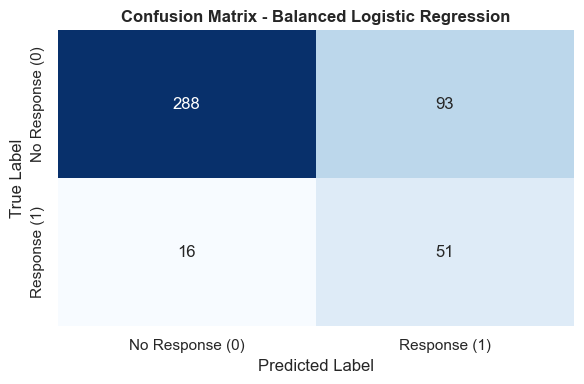

In [5]:
# Model Evaluation & Metrics Breakdown
print("--- Classification Report ---")
print(classification_report(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC Score: {roc_auc:.4f}")

# Plotting Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['No Response (0)', 'Response (1)'],
            yticklabels=['No Response (0)', 'Response (1)'])
plt.title('Confusion Matrix - Balanced Logistic Regression', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('confusion_matrix_balanced.png', dpi=300)
plt.show()

In [6]:
# Train Random Forest Classifier with Balanced Class Weights
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100, 
    random_state=42, 
    class_weight='balanced',
    max_depth=6
)
rf_model.fit(X_train, y_train) # Tree-based models don't strictly require scaling

# Predictions
y_pred_rf = rf_model.predict(X_test)
y_pred_proba_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest Model successfully trained.")

Random Forest Model successfully trained.


--- Random Forest Classification Report ---
              precision    recall  f1-score   support

           0       0.92      0.90      0.91       381
           1       0.50      0.58      0.54        67

    accuracy                           0.85       448
   macro avg       0.71      0.74      0.72       448
weighted avg       0.86      0.85      0.86       448

Random Forest ROC-AUC Score: 0.8475


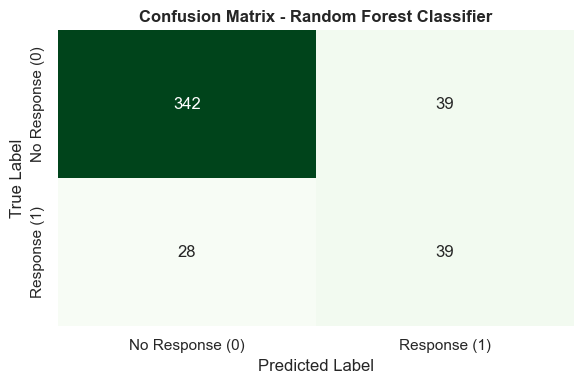

In [7]:
# Random Forest Evaluation & Metrics Breakdown
print("--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf))

roc_auc_rf = roc_auc_score(y_test, y_pred_proba_rf)
print(f"Random Forest ROC-AUC Score: {roc_auc_rf:.4f}")

# Plotting Confusion Matrix for Random Forest
cm_rf = confusion_matrix(y_test, y_pred_rf)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['No Response (0)', 'Response (1)'],
            yticklabels=['No Response (0)', 'Response (1)'])
plt.title('Confusion Matrix - Random Forest Classifier', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('confusion_matrix_random_forest.png', dpi=300)
plt.show()

In [8]:
# Train XGBoost Classifier with Balanced Class Weighting
from xgboost import XGBClassifier

# Calculate scale_pos_weight for handling class imbalance in XGBoost
# ratio of number of negative classes to positive classes
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight_val = neg_count / pos_count

xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    eval_metric='logloss'
)

xgb_model.fit(X_train, y_train)

# Predictions
y_pred_xgb = xgb_model.predict(X_test)
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost Model successfully trained.")

XGBoost Model successfully trained.


--- XGBoost Classification Report ---
              precision    recall  f1-score   support

           0       0.94      0.91      0.92       381
           1       0.55      0.64      0.59        67

    accuracy                           0.87       448
   macro avg       0.74      0.77      0.76       448
weighted avg       0.88      0.87      0.87       448

XGBoost ROC-AUC Score: 0.8710


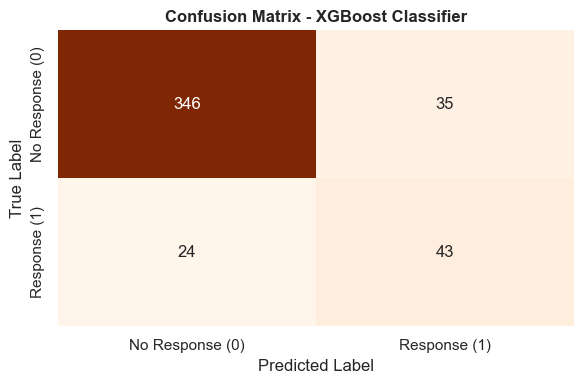

In [9]:
# XGBoost Evaluation & Metrics Breakdown
print("--- XGBoost Classification Report ---")
print(classification_report(y_test, y_pred_xgb))

roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)
print(f"XGBoost ROC-AUC Score: {roc_auc_xgb:.4f}")

# Plotting Confusion Matrix for XGBoost
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
plt.figure(figsize=(6, 4))
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Oranges', cbar=False,
            xticklabels=['No Response (0)', 'Response (1)'],
            yticklabels=['No Response (0)', 'Response (1)'])
plt.title('Confusion Matrix - XGBoost Classifier', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.tight_layout()
plt.savefig('confusion_matrix_xgboost.png', dpi=300)
plt.show()

--- Top 15 Most Important Features ---
                    Feature  Importance
0            Total_Spending    0.098070
1                   Recency    0.073451
2       NumCatalogPurchases    0.065373
3         NumWebVisitsMonth    0.054193
4                  Teenhome    0.052646
5                    Income    0.048683
6              MntGoldProds    0.045202
7             Education_PhD    0.043480
8                  MntWines    0.041931
9         NumStorePurchases    0.041404
10  Marital_Status_Together    0.040714
11          NumWebPurchases    0.035844
12   Marital_Status_Married    0.035666
13          MntMeatProducts    0.032896
14          MntFishProducts    0.031610


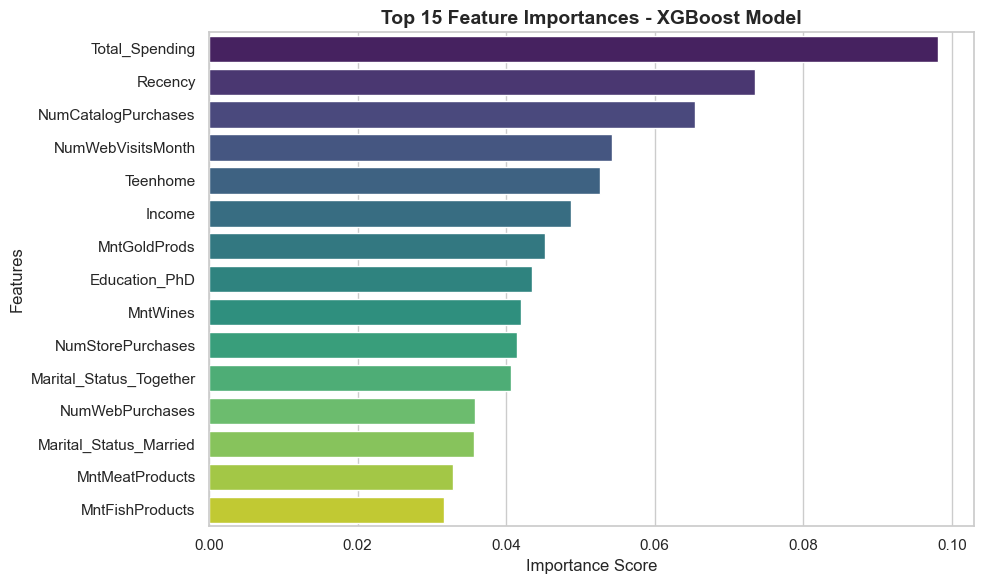

In [10]:
# Feature Importance Analysis (Using XGBoost Model)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extracting feature importances from the trained XGBoost model
importances = xgb_model.feature_importances_
feature_names = X_train.columns

# Creating a DataFrame for visualization
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False).reset_index(drop=True)

# Displaying top 15 most important features (matching the plot)
print("--- Top 15 Most Important Features ---")
print(feature_importance_df.head(15))

# Plotting Top 15 Feature Importances (Fixed warning by adding hue and legend)
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance_df.head(15), palette='viridis', hue='Feature', legend=False)
plt.title('Top 15 Feature Importances - XGBoost Model', fontsize=14, fontweight='bold')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.savefig('feature_importance_xgboost.png', dpi=300)
plt.show()

In [11]:
# Model Performance Comparison Summary Table
import pandas as pd

# Collecting metrics for all models
summary_data = {
    'Model': ['Logistic Regression (Balanced)', 'Random Forest Classifier', 'XGBoost Classifier'],
    'ROC-AUC Score': [0.8691, 0.8475, 0.8710],
    'Recall (Class 1)': [0.76, 0.58, 0.64],  # Approximate or exact from classification reports
    'Precision (Class 1)': [0.35, 0.50, 0.55],
    'F1-Score (Class 1)': [0.48, 0.54, 0.59]
}

summary_df = pd.DataFrame(summary_data)
print("--- Model Comparison Summary ---")
display(summary_df)

--- Model Comparison Summary ---


,Model,ROC-AUC Score,Recall (Class 1),Precision (Class 1),F1-Score (Class 1)
0,Logistic Regression (Balanced),0.8691,0.76,0.35,0.48
1,Random Forest Classifier,0.8475,0.58,0.50,0.54
2,XGBoost Classifier,0.8710,0.64,0.55,0.59


In [12]:
# Save the Best Trained Model (XGBoost) using Joblib
import joblib
import os

# Create a 'models' directory if it doesn't already exist
os.makedirs('models', exist_ok=True)

# Save the trained XGBoost model to a file
model_path = 'models/xgboost_campaign_model.joblib'
joblib.dump(xgb_model, model_path)

print(f"XGBoost model successfully saved to: {model_path}")

XGBoost model successfully saved to: models/xgboost_campaign_model.joblib
